# Porównanie przebiegów weryfikacji

**Po co.** Po prezentacji pipeline'u prowadzący zwrócił uwagę, że bge-m3 jest za słaby do wyszukiwania w dokumentach
naukowych, łączenie rankingów przez RRF jest niepotrzebne, a 69% werdyktów `brak_podstaw` to słabość instrumentu.
Notatnik zestawia przebiegi, w których zmieniono tylko krok werdyktu, na tych samych miarach co w prezentacji
z wynikami (lab3): wypowiedzi sprzeczne w grupach, β1, precyzja i czułość wykrywania sprzeczności na goldzie.

**Co jest stałe.** Gemma 4 12B, tematyczność `topic_v0` (888 wypowiedzi prawicy i 757 reszty) i twierdzenia
`claims_v1` z zamrożonego przebiegu (1636 twierdzeń), prompt werdyktu `verdict_v1` (RAG) albo `paperqa_v0` (PaperQA2).
Zmienia się wyszukiwanie fragmentów AR6 albo całe narzędzie do weryfikacji. Precyzja tematyczności (0,30 prawica,
0,34 reszta) i wynik po korekcie (krok 7) są więc we wszystkich przebiegach takie same.

**Gold.** Próba 100 wypowiedzi z warstwami i wagami z zamrożonego przebiegu, w dwóch wersjach: z repo i z korektą #94
(sprzeczna → niesprzeczna; AR6 przewiduje dla Europy Zachodniej i Środkowej więcej powodzi, WGI TS.4.3.2.5).

**Pliki.** Warianty bge-m3 i Qwen3-Embedding z 20.10 (Ollama 0.40.4) są tylko lokalnie
(`data/processed/retrieval_variants.local/`); bez nich notatnik je pomija. EmbeddingGemma EN i PL, BM25 i PaperQA2
liczono 26–28.10 na Ollamie 0.40.8.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from amc import annotation, estimation, runs, viz
from amc.viz import MUTED, ACCENT, SECOND, SURF, save

viz.setup()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

VERDICT_DIR = ROOT / "data" / "processed" / "verdicts"
LABEL_DIR = ROOT / "data" / "processed" / "labels"
LOCAL_DIR = ROOT / "data" / "processed" / "retrieval_variants.local"
GROUPS = estimation.GROUPS
VERDICTS = ["brak_podstaw", "zgodne", "sprzeczne"]
FROZEN = "zamrożony"
REPEAT = "powtórka zamrożonego"
BOOTSTRAP_REPS = 10_000

RUNS = pd.DataFrame(
    [
        (FROZEN, "RRF: bge-m3 PL + bge-m3 EN + BM25 EN", VERDICT_DIR / "verdict_v1__gemma4_12b.jsonl"),
        (REPEAT, "jak zamrożony (tylko twierdzenia golda)", LOCAL_DIR / "rrf_repeat.jsonl"),
        ("bge-m3 EN", "bge-m3, tekst EN", LOCAL_DIR / "dense_en.jsonl"),
        ("bge-m3 PL", "bge-m3, tekst PL", LOCAL_DIR / "dense_pl.jsonl"),
        ("BM25 EN", "BM25, tekst EN", VERDICT_DIR / "verdict_v1__gemma4_12b__bm25.jsonl"),
        ("Qwen3-Embedding EN", "qwen3-embedding:8b, tekst EN", LOCAL_DIR / "qwen_en.jsonl"),
        ("EmbeddingGemma EN", "embeddinggemma:300m, tekst EN",
         VERDICT_DIR / "verdict_v1__gemma4_12b__en_embeddinggemma_300m.jsonl"),
        ("EmbeddingGemma PL", "embeddinggemma:300m, tekst PL",
         VERDICT_DIR / "verdict_v1__gemma4_12b__pl_embeddinggemma_300m.jsonl"),
        ("PaperQA2", "PaperQA2: embeddinggemma:300m, kawałki PDF",
         VERDICT_DIR / "paperqa_v0__gemma4_12b__embeddinggemma_300m.jsonl"),
    ],
    columns=["przebieg", "wyszukiwanie", "plik"],
).set_index("przebieg")

LABEL_FILES = {
    FROZEN: "gemma4_12b.csv",
    "BM25 EN": "gemma4_12b__bm25.csv",
    "EmbeddingGemma EN": "gemma4_12b__en_embeddinggemma_300m.csv",
    "EmbeddingGemma PL": "gemma4_12b__pl_embeddinggemma_300m.csv",
    "PaperQA2": "gemma4_12b__paperqa_v0__embeddinggemma_300m.csv",
}


def load_verdicts(path):
    rows = runs.last_lines(path, "twierdzenie_id").values()
    verdicts = pd.DataFrame(rows).set_index("twierdzenie_id")
    verdicts.loc[verdicts["blad"].notna(), "werdykt"] = np.nan
    return verdicts


verdicts_by_run = {}
for run_name, path in RUNS["plik"].items():
    if path.exists():
        verdicts_by_run[run_name] = load_verdicts(path)
    else:
        print(f"pomijam {run_name}: brak pliku {path.relative_to(ROOT)}")
RUNS = RUNS.loc[list(verdicts_by_run)]

labels = pd.read_csv(LABEL_DIR / "gemma4_12b.csv")
claims = pd.read_csv(LABEL_DIR / "gemma4_12b_claims.csv", usecols=["twierdzenie_id", "wypowiedz_id"])
design = pd.read_csv(ROOT / "data" / "gold" / "sample.csv")
population_claims = claims["twierdzenie_id"]
full_runs = [name for name, verdicts in verdicts_by_run.items() if population_claims.isin(verdicts.index).all()]

## 1. Werdykty na populacji

Te same 1636 twierdzeń w każdym przebiegu. Zgodność = odsetek twierdzeń z tym samym werdyktem co w zamrożonym
przebiegu; czas = mediana sekund na twierdzenie. Powtórka zamrożonego obejmuje tylko twierdzenia z golda, więc jej tu
nie ma (sekcja 3).

In [2]:
def agreement(verdicts, reference):
    both_present = verdicts.notna() & reference.notna()
    return (verdicts[both_present] == reference[both_present]).mean()


frozen_verdicts = verdicts_by_run[FROZEN].loc[population_claims, "werdykt"]
rows = {}
for run_name in full_runs:
    verdicts = verdicts_by_run[run_name].loc[population_claims]
    shares = verdicts["werdykt"].value_counts(normalize=True).reindex(VERDICTS, fill_value=0) * 100
    row = {"wyszukiwanie": RUNS.loc[run_name, "wyszukiwanie"]}
    for verdict, share in shares.items():
        row[f"{verdict} %"] = share
    row["zgodność z zamrożonym"] = agreement(verdicts["werdykt"], frozen_verdicts)
    row["s / tw."] = verdicts["sekundy"].median()
    rows[run_name] = row

verdict_shares = pd.DataFrame.from_dict(rows, orient="index")
rounding = {f"{verdict} %": 1 for verdict in VERDICTS}
rounding["zgodność z zamrożonym"] = 2
rounding["s / tw."] = 1
verdict_shares.round(rounding)

,wyszukiwanie,brak_podstaw %,zgodne %,sprzeczne %,zgodność z zamrożonym,s / tw.
zamrożony,RRF: bge-m3 PL + bge-m3 EN + BM25 EN,69.4,24.1,6.4,1.00,3.2
bge-m3 EN,"bge-m3, tekst EN",69.7,24.3,6.0,0.91,3.0
bge-m3 PL,"bge-m3, tekst PL",69.7,24.1,6.2,0.90,3.0
BM25 EN,"BM25, tekst EN",73.3,21.6,5.1,0.88,3.2
Qwen3-Embedding EN,"qwen3-embedding:8b, tekst EN",66.6,25.6,7.8,0.88,3.1
EmbeddingGemma EN,"embeddinggemma:300m, tekst EN",66.5,26.3,7.2,0.90,3.0
EmbeddingGemma PL,"embeddinggemma:300m, tekst PL",66.7,25.7,7.6,0.89,3.2
PaperQA2,"PaperQA2: embeddinggemma:300m, kawałki PDF",84.6,11.9,3.4,0.82,25.8


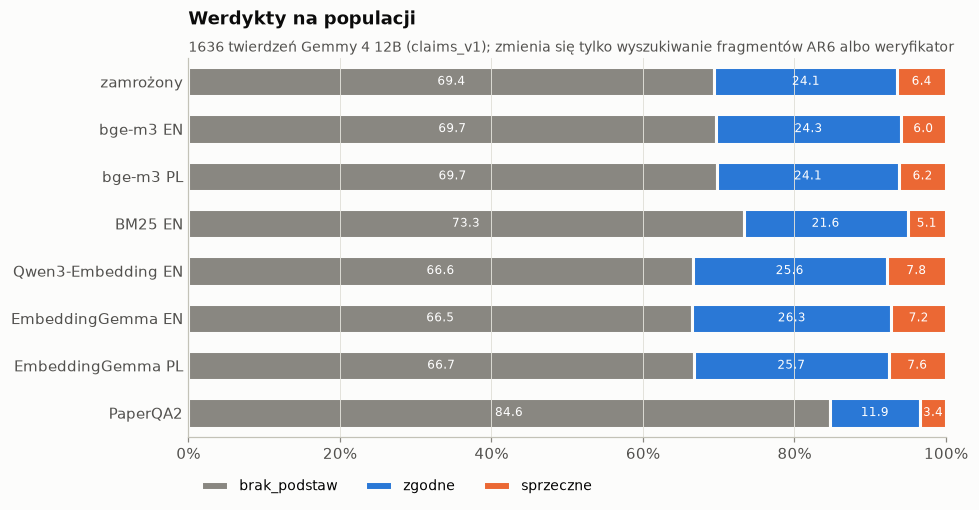

In [3]:
COLORS = {"brak_podstaw": MUTED, "zgodne": ACCENT, "sprzeczne": SECOND}

fig, ax = plt.subplots(figsize=(9, 0.42 * len(full_runs) + 1.4))
bar_rows = np.arange(len(full_runs))
bar_starts = np.zeros(len(full_runs))
for verdict in VERDICTS:
    widths = verdict_shares[f"{verdict} %"].to_numpy(float)
    ax.barh(bar_rows, widths, left=bar_starts, height=0.62, color=COLORS[verdict], edgecolor=SURF, linewidth=2,
            label=verdict)
    for bar_row, start, width in zip(bar_rows, bar_starts, widths):
        if width >= 3:
            ax.text(start + width / 2, bar_row, f"{width:.1f}", ha="center", va="center", fontsize=8, color="white")
    bar_starts += widths

ax.set_yticks(bar_rows, full_runs)
ax.set_ylim(len(full_runs) - 0.5, -0.5)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:g}%"))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Werdykty na populacji")
viz.subtitle(ax, "1636 twierdzeń Gemmy 4 12B (claims_v1); zmienia się tylko wyszukiwanie fragmentów AR6 albo weryfikator")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.08), fontsize=9)
fig.tight_layout()
save(fig, "weryfikacja_01_werdykty")

Żaden sposób wyszukiwania nie zmienia udziału `brak_podstaw` o więcej niż ok. 4 pp (66,5–73,3% wobec 69,4%
w zamrożonym), a werdykt zgadza się z zamrożonym w 88–91% twierdzeń. EmbeddingGemma daje prawie to samo na tekście
angielskim i polskim. PaperQA2 podnosi `brak_podstaw` do 84,6% i jest ok. 8 razy wolniejszy. Wysoki udział
`brak_podstaw` nie wynika więc z wyboru wyszukiwania.

## 2. Wypowiedzi sprzeczne według modelu

Jak na slajdach z pełnym przebiegiem: wypowiedź sprzeczna = wypowiedź o klimacie z co najmniej jednym twierdzeniem
`sprzeczne`, odsetek z 888 wypowiedzi prawicy i 757 reszty. β1 z regresji logistycznej (krok 6, błędy grupowane po
mówcy) z 95% przedziałem. „Inne niż w zamrożonym” = liczba wypowiedzi, które w danym przebiegu mają inną etykietę.

In [4]:
def statement_label(claim_verdicts):
    if claim_verdicts.isna().any():
        return np.nan
    return float((claim_verdicts == "sprzeczne").any())


def statement_labels(verdicts):
    claim_verdicts = claims["twierdzenie_id"].map(verdicts["werdykt"])
    by_statement = claim_verdicts.groupby(claims["wypowiedz_id"]).agg(statement_label)
    has_claims = labels["wypowiedz_id"].isin(by_statement.index)
    contradicting = labels["wypowiedz_id"].map(by_statement).where(has_claims, 0.0)
    return contradicting.where(labels["klimat"] == 1, 0.0)


labels_by_run = {run_name: statement_labels(verdicts) for run_name, verdicts in verdicts_by_run.items()}

# zgodność z etykietami zapisanymi przez label_statements.py
for run_name, file_name in LABEL_FILES.items():
    label_file = LABEL_DIR / file_name
    if run_name in labels_by_run and label_file.exists():
        saved_labels = pd.read_csv(label_file)["sprzeczna"]
        pd.testing.assert_series_equal(labels_by_run[run_name], saved_labels, check_names=False)

In [5]:
topical = labels["klimat"] == 1
topical_in_group = {group: topical & (labels["grupa"] == group) for group in GROUPS}

rows = {}
for run_name in full_runs:
    contradicting = labels_by_run[run_name]
    row = {}
    for group in GROUPS:
        group_labels = contradicting[topical_in_group[group]]
        row[group] = f"{int(group_labels.sum())} ({100 * group_labels.mean():.1f}%)"
    right_share = contradicting[topical_in_group["prawica"]].mean()
    rest_share = contradicting[topical_in_group["reszta"]].mean()
    row["różnica pp"] = 100 * (right_share - rest_share)

    fit = estimation.regression(labels.assign(sprzeczna=contradicting))
    lower = fit["beta1"] - 1.96 * fit["se"]
    upper = fit["beta1"] + 1.96 * fit["se"]
    row["β1 [95% CI]"] = f"{fit['beta1']:.2f} [{lower:.2f}; {upper:.2f}]"
    row["p jednostronne"] = fit["p_jednostronne"]

    changed = contradicting[topical] != labels_by_run[FROZEN][topical]
    row["inne niż w zamrożonym"] = int(changed.sum())
    rows[run_name] = row

group_table = pd.DataFrame.from_dict(rows, orient="index")
group_table.round({"różnica pp": 1, "p jednostronne": 3})

,prawica,reszta,różnica pp,β1 [95% CI],p jednostronne,inne niż w zamrożonym
zamrożony,60 (6.8%),28 (3.7%),3.1,0.63 [0.16; 1.11],0.004,0
bge-m3 EN,57 (6.4%),24 (3.2%),3.2,0.74 [0.26; 1.22],0.001,47
bge-m3 PL,58 (6.5%),25 (3.3%),3.2,0.72 [0.23; 1.20],0.002,51
BM25 EN,48 (5.4%),21 (2.8%),2.6,0.69 [0.17; 1.22],0.005,57
Qwen3-Embedding EN,70 (7.9%),40 (5.3%),2.6,0.43 [0.00; 0.85],0.024,56
EmbeddingGemma EN,61 (6.9%),35 (4.6%),2.2,0.42 [0.00; 0.84],0.024,58
EmbeddingGemma PL,65 (7.3%),36 (4.8%),2.6,0.46 [0.03; 0.88],0.017,47
PaperQA2,35 (3.9%),9 (1.2%),2.8,1.23 [0.50; 1.95],0.000,57


We wszystkich przebiegach prawica ma wyższy odsetek wypowiedzi sprzecznych (różnica 2,2–3,2 pp) i β1 > 0. Etykieta
zmienia się jednak w 47–58 wypowiedziach, czyli w większej liczbie niż wszystkie sprzeczne wypowiedzi reszty
w zamrożonym przebiegu (28). Qwen3-Embedding i EmbeddingGemma dokładają sprzeczne głównie reszcie (35–40 wobec 28),
więc β1 spada do 0,42–0,46 i dolna granica przedziału zbliża się do 0. BM25 zabiera sprzeczne obu grupom (48 i 21),
więc β1 prawie się nie zmienia (0,69); PaperQA2 zabiera je głównie reszcie (9), więc β1 rośnie do 1,23. Kierunek jest
stały, wielkość zależy od weryfikatora.

## 3. Jakość na goldzie

Jak na slajdzie z miarami jakości: precyzja i czułość wykrywania sprzeczności (etykieta końcowa wypowiedzi), z wagami
warstw, w grupach, z 95% przedziałem z bootstrapu warstwowego (10 000 powtórzeń). Etykieta modelu w goldzie pochodzi
z twierdzeń pełnego przebiegu (w warstwie 3 model nie uznał wypowiedzi za tematyczne, więc etykieta to 0). Liczby bez
wag: model = wypowiedzi sprzeczne według modelu, TP, FP i FN względem golda. Korekta #94 zmienia tylko miary reszty.

In [6]:
annotation_files = [ROOT / "data" / "gold" / f"annotations_{initials}.csv" for initials in ("FP", "DK")]
annotations = annotation.load_parts(annotation_files, design)[["kolejnosc", "tematyczna", "sprzeczna"]]
gold_repo = design.merge(annotations, on="kolejnosc")
gold_corrected = gold_repo.copy()
gold_corrected.loc[gold_corrected["kolejnosc"] == 94, "sprzeczna"] = 0
GOLD = {"z repo": gold_repo, "z korektą #94": gold_corrected}

gold_model_labels = {}
for run_name, contradicting in labels_by_run.items():
    by_statement = pd.Series(contradicting.to_numpy(), index=labels["wypowiedz_id"])
    sample_labels = by_statement.reindex(design["wypowiedz_id"]).fillna(0)
    gold_model_labels[run_name] = sample_labels.astype(int).to_numpy()

METRIC_NAMES = {}
for group in GROUPS:
    METRIC_NAMES[f"{group}_etykieta_precyzja"] = f"{group} precyzja"
    METRIC_NAMES[f"{group}_etykieta_TPR"] = f"{group} czułość"
METRIC_KEYS = list(METRIC_NAMES)


def label_quality(gold_arrays, model_labels):
    final_labels = gold_arrays["mt"] * model_labels
    quality = estimation.quality({**gold_arrays, "ms": final_labels})
    return {key: quality[key] for key in METRIC_KEYS}


def bootstrap_intervals(gold, reps=BOOTSTRAP_REPS, seed=2026):
    gold_arrays = estimation.arrays(gold)
    cells = []
    for group, stratum in sorted(set(zip(gold_arrays["grupa"], gold_arrays["warstwa"]))):
        in_cell = (gold_arrays["grupa"] == group) & (gold_arrays["warstwa"] == stratum)
        cells.append(np.flatnonzero(in_cell))

    random_generator = np.random.default_rng(seed)
    rows = []
    for repetition in range(reps):
        resampled = np.concatenate([cell[random_generator.integers(0, len(cell), len(cell))] for cell in cells])
        resampled_arrays = {key: values[resampled] for key, values in gold_arrays.items()}
        for run_name, model_labels in gold_model_labels.items():
            rows.append({"przebieg": run_name, **label_quality(resampled_arrays, model_labels[resampled])})
    samples = pd.DataFrame(rows)
    return samples.groupby("przebieg")[METRIC_KEYS].quantile([0.025, 0.975]).unstack()


def quality_table(version):
    gold_arrays = estimation.arrays(GOLD[version])
    gold_contradicting = gold_arrays["s"].astype(bool)
    intervals = BOOTSTRAP[version]
    rows = {}
    for run_name, model_labels in gold_model_labels.items():
        model_contradicting = (gold_arrays["mt"] * model_labels).astype(bool)
        row = {
            "model": int(model_contradicting.sum()),
            "TP": int((model_contradicting & gold_contradicting).sum()),
            "FP": int((model_contradicting & ~gold_contradicting).sum()),
            "FN": int((~model_contradicting & gold_contradicting).sum()),
        }
        quality = label_quality(gold_arrays, model_labels)
        for key in METRIC_KEYS:
            lower = intervals.loc[run_name, (key, 0.025)]
            upper = intervals.loc[run_name, (key, 0.975)]
            row[METRIC_NAMES[key]] = f"{quality[key]:.2f} [{lower:.2f}; {upper:.2f}]"
        rows[run_name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


BOOTSTRAP = {version: bootstrap_intervals(gold) for version, gold in GOLD.items()}
for version, gold in GOLD.items():
    gold_arrays = estimation.arrays(gold)
    print(f"gold {version}: tematyczne {gold_arrays['t'].sum()}, sprzeczne {gold_arrays['s'].sum()}")
quality_table("z repo")

gold z repo: tematyczne 35, sprzeczne 17
gold z korektą #94: tematyczne 35, sprzeczne 16


,model,TP,FP,FN,prawica precyzja,prawica czułość,reszta precyzja,reszta czułość
zamrożony,40,14,26,3,0.60 [0.40; 0.80],0.25 [0.11; 1.00],0.10 [0.00; 0.25],0.05 [0.00; 1.00]
powtórka zamrożonego,34,14,20,3,0.60 [0.40; 0.80],0.25 [0.11; 1.00],0.14 [0.00; 0.36],0.05 [0.00; 1.00]
bge-m3 EN,28,14,14,3,0.35 [0.14; 0.90],0.25 [0.11; 1.00],0.18 [0.00; 0.44],0.05 [0.00; 1.00]
bge-m3 PL,28,15,13,2,0.86 [0.53; 0.96],0.62 [0.18; 1.00],0.20 [0.00; 0.50],0.05 [0.00; 1.00]
BM25 EN,19,7,12,10,0.54 [0.25; 0.82],0.14 [0.05; 0.69],0.00 [0.00; 0.00],0.00 [0.00; 0.00]
Qwen3-Embedding EN,35,14,21,3,0.63 [0.40; 0.84],0.25 [0.11; 1.00],0.04 [0.00; 0.29],0.05 [0.00; 1.00]
EmbeddingGemma EN,29,13,16,4,0.61 [0.37; 0.83],0.23 [0.10; 1.00],0.04 [0.00; 0.40],0.05 [0.00; 1.00]
EmbeddingGemma PL,32,13,19,4,0.61 [0.37; 0.83],0.23 [0.10; 1.00],0.04 [0.00; 0.31],0.05 [0.00; 1.00]
PaperQA2,15,9,6,8,0.75 [0.47; 1.00],0.18 [0.07; 0.86],0.00 [0.00; 0.00],0.00 [0.00; 0.00]


In [7]:
quality_table("z korektą #94")[["model", "TP", "FP", "FN", "reszta precyzja", "reszta czułość"]]

,model,TP,FP,FN,reszta precyzja,reszta czułość
zamrożony,40,14,26,2,0.10 [0.00; 0.25],1.00 [1.00; 1.00]
powtórka zamrożonego,34,14,20,2,0.14 [0.00; 0.36],1.00 [1.00; 1.00]
bge-m3 EN,28,14,14,2,0.18 [0.00; 0.44],1.00 [1.00; 1.00]
bge-m3 PL,28,15,13,1,0.20 [0.00; 0.50],1.00 [1.00; 1.00]
BM25 EN,19,7,12,9,0.00 [0.00; 0.00],0.00 [0.00; 0.00]
Qwen3-Embedding EN,35,14,21,2,0.04 [0.00; 0.29],1.00 [1.00; 1.00]
EmbeddingGemma EN,29,13,16,3,0.04 [0.00; 0.40],1.00 [1.00; 1.00]
EmbeddingGemma PL,32,13,19,3,0.04 [0.00; 0.31],1.00 [1.00; 1.00]
PaperQA2,15,9,6,7,0.00 [0.00; 0.00],0.00 [0.00; 0.00]


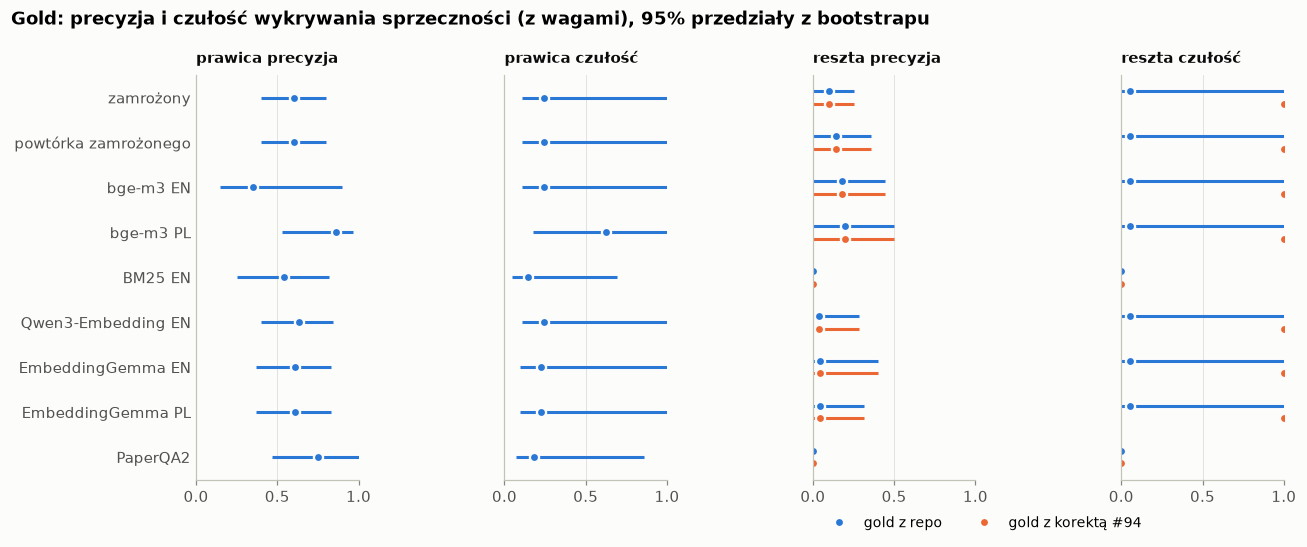

In [8]:
run_names = list(gold_model_labels)
fig, axes = plt.subplots(1, 4, figsize=(12, 0.36 * len(run_names) + 1.8), sharey=True)
for ax, key in zip(axes, METRIC_KEYS):
    if key.startswith("prawica"):
        versions = [("z repo", ACCENT, 0.0)]
    else:
        versions = [("z repo", ACCENT, -0.14), ("z korektą #94", SECOND, 0.14)]
    for version, color, offset in versions:
        gold_arrays = estimation.arrays(GOLD[version])
        points = [label_quality(gold_arrays, gold_model_labels[run_name])[key] for run_name in run_names]
        positions = np.arange(len(run_names)) + offset
        lower = BOOTSTRAP[version].loc[run_names, (key, 0.025)]
        upper = BOOTSTRAP[version].loc[run_names, (key, 0.975)]
        ax.hlines(positions, lower, upper, color=color, lw=2)
        ax.plot(points, positions, "o", ms=6, color=color, mec=SURF, mew=1.5, label=f"gold {version}")
    ax.set_xlim(0, 1)
    ax.set_title(METRIC_NAMES[key], fontsize=10, pad=8)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)

axes[0].set_yticks(range(len(run_names)), run_names)
axes[0].set_ylim(len(run_names) - 0.5, -0.5)
fig.suptitle("Gold: precyzja i czułość wykrywania sprzeczności (z wagami), 95% przedziały z bootstrapu", x=0.01,
             ha="left", fontsize=12, fontweight="bold")
axes[2].legend(loc="upper left", bbox_to_anchor=(0, -0.06), ncol=2, fontsize=9)
fig.tight_layout()
save(fig, "weryfikacja_02_gold")

Bez wag zamrożony przebieg ma 26 fałszywych sprzecznych na 40; warianty wyszukiwania mają ich 12–21, PaperQA2 6, ale
BM25 i PaperQA2 przeoczają 8–10 z 17 sprzecznych (zamrożony 3). Sama powtórka zamrożonego ma 20 zamiast 26, więc część
tych różnic to zmienność samego przebiegu. Przedziały wszystkich przebiegów nakładają się z zamrożonym; wyraźnie
wyższa jest tylko precyzja prawicy w bge-m3 PL (0,86), którą robi jedna wypowiedź (#59, sekcja 4). Po korekcie #94
reszta ma w goldzie tylko dwie sprzeczne wypowiedzi (#4 i #97, warstwa 1); łapie je każdy RAG poza BM25, stąd czułość
reszty 1,00, a w BM25 i PaperQA2 0.

## 4. Kluczowe wypowiedzi z warstwy 2

Wypowiedź z warstwy 2 waży ok. 50–55, czyli kilkanaście razy więcej niż z warstwy 1, więc to te wypowiedzi
przesuwają miary ważone. W tabeli wypowiedzi z warstwy 2 sprzeczne według golda albo któregokolwiek przebiegu
(1 = sprzeczna).

In [9]:
key_statements = design[["kolejnosc", "grupa", "waga"]].copy()
for version, gold in GOLD.items():
    key_statements[f"gold {version}"] = estimation.arrays(gold)["s"]
for run_name, model_labels in gold_model_labels.items():
    key_statements[run_name] = model_labels

label_columns = key_statements.columns[3:]
in_stratum_2 = design["warstwa"] == 2
contradicting_anywhere = key_statements[label_columns].any(axis=1)
key_statements = key_statements[in_stratum_2 & contradicting_anywhere]
key_statements.sort_values(["grupa", "kolejnosc"]).set_index("kolejnosc").round({"waga": 1})

,grupa,waga,gold z repo,gold z korektą #94,zamrożony,powtórka zamrożonego,bge-m3 EN,bge-m3 PL,BM25 EN,Qwen3-Embedding EN,EmbeddingGemma EN,EmbeddingGemma PL,PaperQA2
kolejnosc,,,,,,,,,,,,,
36,prawica,55.2,1,1,0,0,0,0,0,0,0,0,0
59,prawica,55.2,1,1,0,0,0,1,0,0,0,0,0
67,prawica,55.2,0,0,0,0,1,0,0,0,0,0,0
30,reszta,48.6,0,0,0,0,0,0,0,1,1,1,0
94,reszta,48.6,1,0,0,0,0,0,0,0,0,0,0


#36 i #94 nie łapie żaden przebieg, #59 tylko bge-m3 PL. Nowe fałszywe sprzeczne z warstwy 2: #67 (prawica, bge-m3 EN)
i #30 (reszta, biopaliwa, Qwen3-Embedding i EmbeddingGemma EN i PL). Każda taka wypowiedź przesuwa ważoną precyzję
albo czułość grupy o kilkadziesiąt punktów, więc miary ważone porównują przebiegi głównie przez te pięć wypowiedzi.

## 5. Wynik po korekcie (krok 7)

Nie zależy od przebiegu (warstwy i wagi są z zamrożonego), tylko od golda. Dla porównania obie wersje golda.

In [10]:
rows = {}
for version, gold in GOLD.items():
    summary = estimation.summarize(gold, estimation.proportions, BOOTSTRAP_REPS)
    lower_bound = summary.loc["roznica", "dolna_95_jednostronna"]
    rows[version] = {
        "prawica %": 100 * summary.loc["p_prawica", "wartosc"],
        "reszta %": 100 * summary.loc["p_reszta", "wartosc"],
        "różnica pp": 100 * summary.loc["roznica", "wartosc"],
        "dolna granica pp": 100 * lower_bound,
        "hipoteza": "potwierdzona" if lower_bound > 0 else "niepotwierdzona",
    }
pd.DataFrame.from_dict(rows, orient="index").round(1)

,prawica %,reszta %,różnica pp,dolna granica pp,hipoteza
z repo,55.1,19.9,35.2,-11.2,niepotwierdzona
z korektą #94,55.1,1.1,54.0,18.2,potwierdzona


## Podsumowanie (szkic)

- Zmiana wyszukiwania (bez RRF, inny model embeddingów, tekst EN albo PL) przesuwa `brak_podstaw` najwyżej o ok. 4 pp
  i nie poprawia jakości na goldzie bardziej, niż zmienia ją powtórzenie tego samego przebiegu.
- PaperQA2 jest ostrożniejszy (6 fałszywych sprzecznych zamiast 26, ale 8 przeoczeń zamiast 3) i ok. 8 razy wolniejszy.
- Według modelu prawica ma więcej wypowiedzi sprzecznych w każdym przebiegu. Wynik po korekcie od przebiegu nie zależy,
  tylko od golda: z korektą #94 hipoteza jest potwierdzona (dolna granica +18,2 pp), bez niej nie (−11,2 pp).